# 04b — Model diagnostics and drift

## Purpose
Notebook 04 selected the unweighted LightGBM challenger, fitted an isotonic mapping on 2014, and evaluated it on 2015. This notebook adds the diagnostics that Notebook 04 did not report, **without retraining or overwriting any saved model**:

1. Discrimination for all three models on 2014 and 2015 (AUC, Gini, KS) with bootstrap confidence intervals, including the logistic-regression baseline on the 2015 test period.
2. Calibration diagnostics beyond the reliability plot: calibration slope, calibration-in-the-large, and numeric decile tables. It also tests whether the isotonic step actually beat simpler recalibrations that are frozen on 2014 data.
3. Population Stability Index (PSI) for every model input and for the predicted score.
4. A decomposition of the rise in charge-off rates into *mix shift* (the portfolio contains riskier segments) and *within-segment deterioration* (the same kind of loan charges off more often).
5. Month-by-month calibration and discrimination drift through 2014–2015.

## Inputs and rules
* Reads the saved preprocessor, raw LightGBM and isotonic-calibrated model from `models/checkpoints/`. Nothing in that folder is modified.
* The logistic-regression baseline was not saved by Notebook 04, so it is refitted here with the identical settings. The cell that does so first checks that its 2014 results reproduce Notebook 04.
* 2015 outcomes are used only to **evaluate**. Every recalibration is fitted on 2014 data and applied unchanged to 2015.
* The target is a recorded final Charged Off versus Fully Paid status, not default within a fixed horizon.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.sparse import issparse
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, roc_curve

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.features.credit_features import (
    BASELINE_FEATURES,
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    make_row_features,
    split_by_issue_month,
)

# When True, the refitted baseline and the saved models must reproduce the
# Notebook 04 validation numbers (to four decimals) or this notebook stops.
STRICT_REFERENCE_CHECKS = True
N_BOOT = 200
RANDOM_SEED = 42

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Setup complete.")

Setup complete.


## 1. Load data and frozen artifacts

In [2]:
pd_file = project_root / "data" / "processed" / "pd_cohort_2011_2015_36m.parquet"
checkpoints = project_root / "models" / "checkpoints"

data = pd.read_parquet(pd_file)
splits = split_by_issue_month(data)

train_ready = make_row_features(splits["train"])
validation_ready = make_row_features(splits["validation"])
test_ready = make_row_features(splits["test"])

preprocessor = joblib.load(checkpoints / "baseline_preprocessor_2011_2013.joblib")
lgb_raw = joblib.load(checkpoints / "lightgbm_challenger_unweighted.joblib")
lgb_isotonic = joblib.load(
    checkpoints / "calibrated_lightgbm_unweighted_isotonic.joblib"
)

assert list(preprocessor.feature_names_in_) == list(BASELINE_FEATURES)

feature_names = preprocessor.get_feature_names_out()


def named_matrix(frame):
    matrix = preprocessor.transform(frame[BASELINE_FEATURES])
    if issparse(matrix):
        return pd.DataFrame.sparse.from_spmatrix(
            matrix, index=frame.index, columns=feature_names
        )
    return pd.DataFrame(matrix, index=frame.index, columns=feature_names)


X_train = named_matrix(train_ready)
X_val = named_matrix(validation_ready)
X_test = named_matrix(test_ready)

y_train = train_ready["charged_off"].to_numpy()
y_val = validation_ready["charged_off"].to_numpy()
y_test = test_ready["charged_off"].to_numpy()

print(f"Train {len(y_train):,} | Validation {len(y_val):,} | Test {len(y_test):,}")

Train 157,993 | Validation 162,570 | Test 283,026


## 2. Refit the logistic-regression baseline and verify against Notebook 04
The logistic regression uses the settings from Notebook 04 (`max_iter=1000`, `random_state=42`, no class weights). Before using it, confirm that it and the saved LightGBM reproduce the 2014 numbers that Notebook 04 printed: AUC 0.6551 (LR) and 0.6600 (LightGBM), and LightGBM mean predicted risk 0.1305.

In [3]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

scores = {
    "Logistic regression": {
        "val": lr.predict_proba(X_val)[:, 1],
        "test": lr.predict_proba(X_test)[:, 1],
    },
    "LightGBM raw": {
        "val": lgb_raw.predict_proba(X_val)[:, 1],
        "test": lgb_raw.predict_proba(X_test)[:, 1],
    },
    "LightGBM isotonic (fit on 2014)": {
        "val": lgb_isotonic.predict_proba(X_val)[:, 1],
        "test": lgb_isotonic.predict_proba(X_test)[:, 1],
    },
}

reference = {
    "LR validation AUC": (roc_auc_score(y_val, scores["Logistic regression"]["val"]), 0.6551),
    "LightGBM validation AUC": (roc_auc_score(y_val, scores["LightGBM raw"]["val"]), 0.6600),
    "LightGBM validation mean prediction": (scores["LightGBM raw"]["val"].mean(), 0.1305),
}

for label, (observed, expected) in reference.items():
    ok = abs(observed - expected) <= 6e-4
    print(f"{label}: {observed:.4f} (Notebook 04: {expected:.4f}) -> {'OK' if ok else 'MISMATCH'}")
    if STRICT_REFERENCE_CHECKS and not ok:
        raise AssertionError(
            f"{label} does not reproduce Notebook 04. Check that the saved "
            "checkpoints and the processed data are the ones Notebook 04 used."
        )

LR validation AUC: 0.6551 (Notebook 04: 0.6551) -> OK
LightGBM validation AUC: 0.6600 (Notebook 04: 0.6600) -> OK
LightGBM validation mean prediction: 0.1305 (Notebook 04: 0.1305) -> OK


## 3. Discrimination: AUC, Gini, KS
Gini is `2·AUC − 1`. KS is the maximum separation between the cumulative score distributions of the two outcome classes. The isotonic mapping is monotone, so it can only change AUC through ties it creates; any AUC difference between raw and isotonic LightGBM is a tie effect, not a change in ranking quality.

In [4]:
def ks_statistic(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


rows = []
for model, by_period in scores.items():
    for period, y in [("2014 validation", y_val), ("2015 test", y_test)]:
        p = by_period["val" if period.startswith("2014") else "test"]
        auc = roc_auc_score(y, p)
        rows.append(
            {
                "model": model,
                "period": period,
                "auc": auc,
                "gini": 2 * auc - 1,
                "ks": ks_statistic(y, p),
            }
        )

discrimination = pd.DataFrame(rows)
display(discrimination.round(4))

,model,period,auc,gini,ks
0,Logistic regression,2014 validation,0.6551,0.3103,0.2264
1,Logistic regression,2015 test,0.6569,0.3139,0.2253
2,LightGBM raw,2014 validation,0.6600,0.3200,0.2322
3,LightGBM raw,2015 test,0.6625,0.3251,0.2362
4,LightGBM isotonic (fit on 2014),2014 validation,0.6606,0.3212,0.2322
5,LightGBM isotonic (fit on 2014),2015 test,0.6624,0.3248,0.2360


### Bootstrap confidence intervals on the 2015 test set
Loans are resampled with replacement (`N_BOOT` times, same resample for every model), so differences between models are **paired**. These intervals reflect sampling noise only; they do not capture the uncertainty from using one historical period.

In [5]:
rng = np.random.default_rng(RANDOM_SEED)
n_test = len(y_test)
names = list(scores)

boot_auc = {name: [] for name in names}
boot_brier_gap = []  # raw LightGBM Brier minus isotonic LightGBM Brier

raw_p = scores["LightGBM raw"]["test"]
iso_p = scores["LightGBM isotonic (fit on 2014)"]["test"]

for _ in range(N_BOOT):
    idx = rng.integers(0, n_test, n_test)
    yb = y_test[idx]
    for name in names:
        boot_auc[name].append(roc_auc_score(yb, scores[name]["test"][idx]))
    boot_brier_gap.append(
        np.mean((raw_p[idx] - yb) ** 2) - np.mean((iso_p[idx] - yb) ** 2)
    )


def interval(values):
    lo, hi = np.percentile(values, [2.5, 97.5])
    return float(lo), float(hi)


ci_rows = []
for name in names:
    lo, hi = interval(boot_auc[name])
    ci_rows.append(
        {
            "model": name,
            "test_auc": roc_auc_score(y_test, scores[name]["test"]),
            "auc_ci_low": lo,
            "auc_ci_high": hi,
        }
    )
auc_ci = pd.DataFrame(ci_rows)
display(auc_ci.round(4))

diff = np.array(boot_auc["LightGBM raw"]) - np.array(boot_auc["Logistic regression"])
lo, hi = interval(diff)
print(f"LightGBM raw minus logistic regression, test AUC: "
      f"{diff.mean():+.4f} (95% interval {lo:+.4f} to {hi:+.4f})")

lo, hi = interval(boot_brier_gap)
print(f"Brier(raw) minus Brier(isotonic), test: "
      f"{np.mean(boot_brier_gap):+.5f} (95% interval {lo:+.5f} to {hi:+.5f})")
print("A positive Brier gap means the isotonic version scored better. "
      "An interval that includes zero means the improvement is not distinguishable from noise.")

,model,test_auc,auc_ci_low,auc_ci_high
0,Logistic regression,0.6569,0.6545,0.6596
1,LightGBM raw,0.6625,0.6598,0.6655
2,LightGBM isotonic (fit on 2014),0.6624,0.6597,0.6654


LightGBM raw minus logistic regression, test AUC: +0.0057 (95% interval +0.0045 to +0.0072)
Brier(raw) minus Brier(isotonic), test: +0.00027 (95% interval +0.00025 to +0.00030)
A positive Brier gap means the isotonic version scored better. An interval that includes zero means the improvement is not distinguishable from noise.


## 4. Calibration diagnostics
For each model and period:

* **Observed / predicted** is the observed charge-off rate divided by the mean predicted probability. Above 1 means under-prediction.
* **Calibration-in-the-large** is the log-odds shift that would make the mean prediction match the observed rate, holding the slope at 1. Positive means under-prediction.
* **Calibration slope** (with intercept) comes from regressing the outcome on the logit of the prediction. A slope near 1 means the spread of predictions is right; below 1 means predictions are too extreme.

The isotonic model's 2014 row is **in-sample**, because the mapping was fitted on 2014 outcomes. Only the 2015 rows are out-of-time.

In [6]:
EPS = 1e-6


def calibration_summary(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    z = logit(p)

    slope_fit = sm.Logit(y, sm.add_constant(z)).fit(disp=0)
    intercept, slope = slope_fit.params

    shift_fit = sm.GLM(
        y,
        np.ones((len(y), 1)),
        family=sm.families.Binomial(),
        offset=z,
    ).fit()

    return {
        "mean_predicted": float(p.mean()),
        "observed": float(np.mean(y)),
        "observed_over_predicted": float(np.mean(y) / p.mean()),
        "calibration_in_the_large": float(shift_fit.params[0]),
        "calibration_slope": float(slope),
        "calibration_intercept": float(intercept),
        "brier": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p)),
    }


calibration_rows = []
for model, by_period in scores.items():
    for period, y, key in [
        ("2014 validation", y_val, "val"),
        ("2015 test", y_test, "test"),
    ]:
        row = {"model": model, "period": period}
        row.update(calibration_summary(y, by_period[key]))
        calibration_rows.append(row)

calibration = pd.DataFrame(calibration_rows)
display(calibration.round(4))

,model,period,mean_predicted,observed,observed_over_predicted,calibration_in_the_large,calibration_slope,calibration_intercept,brier,log_loss
0,Logistic regression,2014 validation,0.1326,0.1373,1.0353,0.0418,0.9359,-0.0715,0.1144,0.3824
1,Logistic regression,2015 test,0.1297,0.1489,1.1477,0.1671,0.9415,0.0618,0.1223,0.4028
2,LightGBM raw,2014 validation,0.1305,0.1373,1.0515,0.0603,1.0125,0.0825,0.1140,0.3808
3,LightGBM raw,2015 test,0.1287,0.1489,1.1570,0.1762,1.0160,0.2050,0.1219,0.4011
4,LightGBM isotonic (fit on 2014),2014 validation,0.1373,0.1373,1.0000,-0.0000,1.0000,0.0000,0.1138,0.3803
5,LightGBM isotonic (fit on 2014),2015 test,0.1352,0.1489,1.1008,0.1167,0.9912,0.1015,0.1216,0.4001


### Numeric decile tables, 2015 test
Equal-sized bins by predicted score (ties broken by rank). The `gap` column is observed minus predicted, in probability points. If the gap is positive in almost every bin, the problem is a level shift, not a problem with a particular score region.

In [7]:
def decile_table(y, p, q=10):
    frame = pd.DataFrame({"y": y, "p": p})
    frame["bin"] = pd.qcut(frame["p"].rank(method="first"), q, labels=False) + 1
    table = frame.groupby("bin").agg(
        loans=("y", "size"),
        mean_predicted=("p", "mean"),
        observed=("y", "mean"),
    )
    table["gap"] = table["observed"] - table["mean_predicted"]
    return table


for name in ["LightGBM raw", "LightGBM isotonic (fit on 2014)"]:
    print(f"\n{name} - 2015 test")
    display(decile_table(y_test, scores[name]["test"]).round(4))


LightGBM raw - 2015 test


,loans,mean_predicted,observed,gap
bin,,,,
1,28303,0.0388,0.0391,0.0003
2,28303,0.0632,0.0724,0.0092
3,28302,0.0801,0.0932,0.0131
4,28303,0.0954,0.1121,0.0167
5,28302,0.1106,0.1306,0.0200
6,28303,0.1270,0.1540,0.0270
7,28302,0.1457,0.1747,0.0290
8,28303,0.1682,0.1934,0.0252
9,28302,0.1981,0.2304,0.0323



LightGBM isotonic (fit on 2014) - 2015 test


,loans,mean_predicted,observed,gap
bin,,,,
1,28303,0.0357,0.0389,0.0033
2,28303,0.0657,0.0725,0.0067
3,28302,0.0829,0.0936,0.0107
4,28303,0.1034,0.1118,0.0084
5,28302,0.1166,0.1321,0.0155
6,28303,0.1337,0.1522,0.0185
7,28302,0.1575,0.1747,0.0172
8,28303,0.1794,0.1946,0.0152
9,28302,0.2076,0.2296,0.0220


### Does isotonic beat simpler recalibrations?
Three alternatives are fitted on **2014 only** and applied unchanged to 2015:

* **Intercept shift:** adds the 2014 calibration-in-the-large to the raw log-odds.
* **Platt (2014):** logistic recalibration of the raw log-odds (slope and intercept) fitted on all of 2014.
* **Platt (2014 H2):** the same, fitted only on loans issued July–December 2014, the most recent data available before 2015.

This is the same information set the isotonic mapping had. A simpler method that matches or beats isotonic is easier to justify and usually more stable.

In [8]:
raw_val = np.clip(scores["LightGBM raw"]["val"], EPS, 1 - EPS)
raw_test = np.clip(scores["LightGBM raw"]["test"], EPS, 1 - EPS)
z_val, z_test = logit(raw_val), logit(raw_test)


def platt_fit(z, y):
    fit = sm.Logit(y, sm.add_constant(z)).fit(disp=0)
    return fit.params  # intercept, slope


shift = sm.GLM(
    y_val,
    np.ones((len(y_val), 1)),
    family=sm.families.Binomial(),
    offset=z_val,
).fit().params[0]

a_all, b_all = platt_fit(z_val, y_val)

h2_mask = (validation_ready["issue_month"] >= "2014-07-01").to_numpy()
a_h2, b_h2 = platt_fit(z_val[h2_mask], y_val[h2_mask])

alternatives = {
    "Raw LightGBM (no recalibration)": raw_test,
    "Isotonic (fit on 2014)": scores["LightGBM isotonic (fit on 2014)"]["test"],
    "Intercept shift (2014)": expit(z_test + shift),
    "Platt (2014)": expit(a_all + b_all * z_test),
    "Platt (2014 H2 only)": expit(a_h2 + b_h2 * z_test),
}

rows = []
for name, p in alternatives.items():
    row = {"method": name}
    row.update(calibration_summary(y_test, p))
    row["auc"] = roc_auc_score(y_test, p)
    rows.append(row)

recalibration = pd.DataFrame(rows).set_index("method")
display(
    recalibration[
        [
            "mean_predicted",
            "observed_over_predicted",
            "calibration_in_the_large",
            "calibration_slope",
            "brier",
            "log_loss",
            "auc",
        ]
    ].round(4)
)
print(f"Fitted on 2014: intercept shift {shift:+.4f}; Platt a={a_all:+.4f}, b={b_all:.4f}; "
      f"Platt H2 a={a_h2:+.4f}, b={b_h2:.4f}")

,mean_predicted,observed_over_predicted,calibration_in_the_large,calibration_slope,brier,log_loss,auc
method,,,,,,,
Raw LightGBM (no recalibration),0.1287,1.1570,0.1762,1.0160,0.1219,0.4011,0.6625
Isotonic (fit on 2014),0.1352,1.1008,0.1167,0.9912,0.1216,0.4001,0.6624
Intercept shift (2014),0.1353,1.1002,0.1160,1.0160,0.1216,0.4001,0.6625
Platt (2014),0.1353,1.1003,0.1162,1.0034,0.1216,0.4001,0.6625
Platt (2014 H2 only),0.1382,1.0775,0.0910,0.9957,0.1216,0.3998,0.6625


Fitted on 2014: intercept shift +0.0603; Platt a=+0.0825, b=1.0125; Platt H2 a=+0.1219, b=1.0203


### Reliability plot, 2015 test

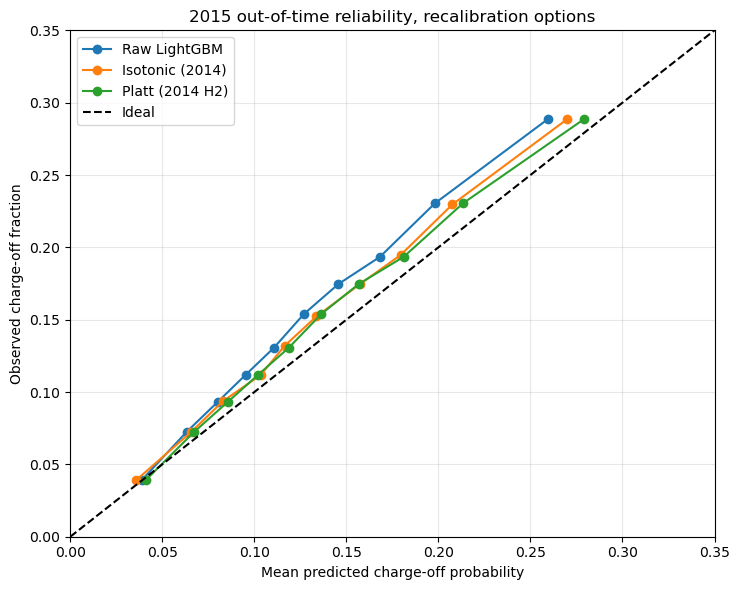

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6))

for name, p in [
    ("Raw LightGBM", raw_test),
    ("Isotonic (2014)", alternatives["Isotonic (fit on 2014)"]),
    ("Platt (2014 H2)", alternatives["Platt (2014 H2 only)"]),
]:
    table = decile_table(y_test, p)
    ax.plot(table["mean_predicted"], table["observed"], marker="o", label=name)

upper = 0.35
ax.plot([0, upper], [0, upper], "k--", label="Ideal")
ax.set_xlim(0, upper)
ax.set_ylim(0, upper)
ax.set_xlabel("Mean predicted charge-off probability")
ax.set_ylabel("Observed charge-off fraction")
ax.set_title("2015 out-of-time reliability, recalibration options")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "04b_reliability_recalibration_2015.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Population Stability Index (PSI)
PSI compares a reference distribution with a comparison distribution. Continuous numeric variables are binned on **reference-period** quantiles plus a separate missing bin. Numeric variables with 20 or fewer distinct values (delinquency counts, public records, flags) are compared by the share of each value instead, because quantile bins collapse to a single bin for zero-inflated variables and would hide a change in the share of non-zero values. Categorical variables use category shares, with unseen categories counted. The usual rule of thumb is below 0.10 stable, 0.10 to 0.25 moderate shift, and above 0.25 major shift. It is a convention, not a statistical test.

The two functions below reproduce Notebook 04's numeric PSI. The cell first checks that against the values Notebook 04 printed (DTI 0.0638, interest rate 0.2945).

In [10]:
def _psi(reference_share, comparison_share, epsilon=1e-6):
    ref = np.asarray(reference_share, dtype=float) + epsilon
    cmp_ = np.asarray(comparison_share, dtype=float) + epsilon
    ref = ref / ref.sum()
    cmp_ = cmp_ / cmp_.sum()
    return float(((cmp_ - ref) * np.log(cmp_ / ref)).sum())


def psi_numeric(reference, comparison, buckets=10):
    reference = pd.to_numeric(pd.Series(reference), errors="coerce")
    comparison = pd.to_numeric(pd.Series(comparison), errors="coerce")
    ref_valid = reference.dropna().to_numpy()
    cmp_valid = comparison.dropna().to_numpy()

    edges = np.unique(np.quantile(ref_valid, np.linspace(0, 1, buckets + 1)))
    if len(edges) < 2:
        return float("nan")
    edges[0], edges[-1] = -np.inf, np.inf

    ref_counts = np.append(np.histogram(ref_valid, bins=edges)[0], reference.isna().sum())
    cmp_counts = np.append(np.histogram(cmp_valid, bins=edges)[0], comparison.isna().sum())
    return _psi(ref_counts / len(reference), cmp_counts / len(comparison))


def psi_categorical(reference, comparison):
    ref = pd.Series(reference).astype("string").fillna("__missing__")
    cmp_ = pd.Series(comparison).astype("string").fillna("__missing__")
    categories = sorted(set(ref.dropna().unique()) | set(cmp_.dropna().unique()))
    ref_share = ref.value_counts(normalize=True).reindex(categories).fillna(0.0)
    cmp_share = cmp_.value_counts(normalize=True).reindex(categories).fillna(0.0)
    return _psi(ref_share.to_numpy(), cmp_share.to_numpy())


def psi_label(value):
    if not np.isfinite(value):
        return "n/a"
    if value < 0.10:
        return "stable"
    if value < 0.25:
        return "moderate"
    return "major"


DISCRETE_MAX_VALUES = 20


def psi_feature(reference, comparison):
    # Quantile-bin PSI for continuous inputs; value-share PSI for inputs with
    # few distinct values (counts and flags), where quantile bins would collapse.
    reference = pd.Series(reference)
    if reference.nunique(dropna=True) <= DISCRETE_MAX_VALUES:
        return psi_categorical(reference, comparison), "discrete values"
    return psi_numeric(reference, comparison), "quantile bins"


check_dti = psi_numeric(train_ready["dti"], test_ready["dti"])
check_int = psi_numeric(train_ready["int_rate"], test_ready["int_rate"])
print(f"DTI PSI, train vs test: {check_dti:.4f} (Notebook 04: 0.0638)")
print(f"Interest-rate PSI, train vs test: {check_int:.4f} (Notebook 04: 0.2945)")
if STRICT_REFERENCE_CHECKS:
    assert abs(check_dti - 0.0638) <= 6e-4
    assert abs(check_int - 0.2945) <= 6e-4

DTI PSI, train vs test: 0.0638 (Notebook 04: 0.0638)
Interest-rate PSI, train vs test: 0.2945 (Notebook 04: 0.2945)


### PSI for every model input
Reference is the 2011–2013 training period. `int_rate` and `grade` are **not** model inputs; they are listed afterwards as context for the pricing shift.

In [11]:
psi_rows = []

for feature in NUMERIC_FEATURES:
    psi_2014, method = psi_feature(train_ready[feature], validation_ready[feature])
    psi_2015, _ = psi_feature(train_ready[feature], test_ready[feature])
    psi_rows.append(
        {
            "feature": feature,
            "type": "numeric",
            "method": method,
            "psi_train_vs_2014": psi_2014,
            "psi_train_vs_2015": psi_2015,
        }
    )

for feature in CATEGORICAL_FEATURES:
    psi_rows.append(
        {
            "feature": feature,
            "type": "categorical",
            "method": "category shares",
            "psi_train_vs_2014": psi_categorical(train_ready[feature], validation_ready[feature]),
            "psi_train_vs_2015": psi_categorical(train_ready[feature], test_ready[feature]),
        }
    )

psi_inputs = (
    pd.DataFrame(psi_rows)
    .assign(status_2015=lambda d: d["psi_train_vs_2015"].map(psi_label))
    .sort_values("psi_train_vs_2015", ascending=False)
    .reset_index(drop=True)
)
display(psi_inputs.round(4))

context_rows = [
    {
        "variable": "int_rate (not a model input)",
        "psi_train_vs_2014": psi_numeric(train_ready["int_rate"], validation_ready["int_rate"]),
        "psi_train_vs_2015": psi_numeric(train_ready["int_rate"], test_ready["int_rate"]),
    },
    {
        "variable": "grade (not a model input)",
        "psi_train_vs_2014": psi_categorical(train_ready["grade"], validation_ready["grade"]),
        "psi_train_vs_2015": psi_categorical(train_ready["grade"], test_ready["grade"]),
    },
]
print("\nContext variables")
display(pd.DataFrame(context_rows).round(4))

,feature,type,method,psi_train_vs_2014,psi_train_vs_2015,status_2015
0,verification_status,categorical,category shares,0.1167,0.1805,moderate
1,pub_rec,numeric,discrete values,0.0890,0.0924,stable
2,addr_state,categorical,category shares,0.0396,0.0809,stable
3,purpose,categorical,category shares,0.0607,0.0751,stable
4,dti,numeric,quantile bins,0.0206,0.0638,stable
5,inq_last_6mths,numeric,discrete values,0.0088,0.0543,stable
6,revol_util,numeric,quantile bins,0.0251,0.0459,stable
7,credit_history_months,numeric,quantile bins,0.0356,0.0446,stable
8,fico_midpoint,numeric,quantile bins,0.0572,0.0431,stable
9,collections_12_mths_ex_med,numeric,discrete values,0.0206,0.0347,stable



Context variables


,variable,psi_train_vs_2014,psi_train_vs_2015
0,int_rate (not a model input),0.0760,0.2945
1,grade (not a model input),0.0325,0.0290


### PSI of the predicted score
Two references are shown. **2014 to 2015** compares two out-of-sample score distributions and is the cleaner measure. **Train to 2015** is shown for completeness, but training-period scores from LightGBM are in-sample and more extreme, which inflates that comparison.

In [12]:
train_raw_score = lgb_raw.predict_proba(X_train)[:, 1]

score_psi = pd.DataFrame(
    [
        {
            "score": "LightGBM raw",
            "reference": "2014 validation",
            "comparison": "2015 test",
            "psi": psi_numeric(scores["LightGBM raw"]["val"], scores["LightGBM raw"]["test"]),
        },
        {
            "score": "LightGBM isotonic",
            "reference": "2014 validation",
            "comparison": "2015 test",
            "psi": psi_numeric(
                scores["LightGBM isotonic (fit on 2014)"]["val"],
                scores["LightGBM isotonic (fit on 2014)"]["test"],
            ),
        },
        {
            "score": "LightGBM raw",
            "reference": "2011-2013 train (in-sample)",
            "comparison": "2015 test",
            "psi": psi_numeric(train_raw_score, scores["LightGBM raw"]["test"]),
        },
        {
            "score": "Logistic regression",
            "reference": "2014 validation",
            "comparison": "2015 test",
            "psi": psi_numeric(
                scores["Logistic regression"]["val"], scores["Logistic regression"]["test"]
            ),
        },
    ]
)
score_psi["status"] = score_psi["psi"].map(psi_label)
display(score_psi.round(4))

,score,reference,comparison,psi,status
0,LightGBM raw,2014 validation,2015 test,0.0013,stable
1,LightGBM isotonic,2014 validation,2015 test,0.0012,stable
2,LightGBM raw,2011-2013 train (in-sample),2015 test,0.0029,stable
3,Logistic regression,2014 validation,2015 test,0.0020,stable


## 6. Is the drift mix shift or within-segment deterioration?
The observed charge-off rate rose from 12.52% (2011–2013) to 13.73% (2014) to 14.89% (2015). Two different stories produce that:

* **Mix effect:** the portfolio shifted toward segments that were already riskier.
* **Rate effect:** within the same segment, loans charged off more often than before.

The decomposition is exact: `change = Σ(w_new − w_base)·r_base + Σ w_new·(r_new − r_base)`, where `w` is the segment's share of loans and `r` its charge-off rate. The first term is the mix effect and the second the rate effect.

Two segmentations are used. **Lending Club grade** is the lender's own risk label; it is not a model input but is a natural segmentation. **Model-score bins** use deciles of the 2014 raw LightGBM score; a large rate effect there means loans with the *same* predicted risk performed worse in 2015, which is exactly why the model under-predicts.

In [13]:
def kitagawa(base, new, segment, target="charged_off"):
    b = base.groupby(segment, observed=True)[target].agg(["size", "mean"])
    n = new.groupby(segment, observed=True)[target].agg(["size", "mean"])
    segments = b.index.union(n.index)

    w_base = (b["size"] / b["size"].sum()).reindex(segments).fillna(0.0)
    w_new = (n["size"] / n["size"].sum()).reindex(segments).fillna(0.0)
    r_base = b["mean"].reindex(segments)
    r_new = n["mean"].reindex(segments)
    r_base = r_base.fillna(r_new)
    r_new = r_new.fillna(r_base)

    mix = float(((w_new - w_base) * r_base).sum())
    rate = float((w_new * (r_new - r_base)).sum())
    total = float(new[target].mean() - base[target].mean())
    assert np.isclose(mix + rate, total, atol=1e-10)

    return {
        "base_rate": float(base[target].mean()),
        "new_rate": float(new[target].mean()),
        "total_change": total,
        "mix_effect": mix,
        "rate_effect": rate,
    }


# Score bins: edges from the 2014 raw-score deciles (out-of-sample for both periods).
edges = np.unique(np.quantile(scores["LightGBM raw"]["val"], np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf

val_seg = validation_ready.assign(
    score_bin=pd.cut(scores["LightGBM raw"]["val"], edges, labels=False)
)
test_seg = test_ready.assign(
    score_bin=pd.cut(scores["LightGBM raw"]["test"], edges, labels=False)
)

comparisons = [
    ("Grade", "2011-2013 to 2015", train_ready, test_seg, "grade"),
    ("Grade", "2014 to 2015", val_seg, test_seg, "grade"),
    ("Score decile (2014 edges)", "2014 to 2015", val_seg, test_seg, "score_bin"),
]

decomposition = pd.DataFrame(
    [
        {"segmentation": seg, "periods": label, **kitagawa(base, new, col)}
        for seg, label, base, new, col in comparisons
    ]
)
for column in ["base_rate", "new_rate", "total_change", "mix_effect", "rate_effect"]:
    decomposition[column] = decomposition[column] * 100

print("All values in percentage points.")
display(decomposition.round(3))

All values in percentage points.


,segmentation,periods,base_rate,new_rate,total_change,mix_effect,rate_effect
0,Grade,2011-2013 to 2015,12.520,14.886,2.367,-0.040,2.407
1,Grade,2014 to 2015,13.726,14.886,1.160,-0.576,1.735
2,Score decile (2014 edges),2014 to 2015,13.726,14.886,1.160,-0.203,1.363


In [14]:
all_years = pd.concat([train_ready, validation_ready, test_ready])
all_years["issue_year"] = all_years["issue_month"].dt.year

grade_mix = pd.crosstab(all_years["issue_year"], all_years["grade"], normalize="index") * 100
grade_rate = (
    all_years.pivot_table(
        index="issue_year", columns="grade", values="charged_off", aggfunc="mean"
    )
    * 100
)

print("Grade mix by issue year (% of loans)")
display(grade_mix.round(1))
print("Observed charge-off rate by grade and issue year (%)")
display(grade_rate.round(1))

Grade mix by issue year (% of loans)


grade,A,B,C,D,E,F,G
issue_year,,,,,,,
2011,39.6,33.5,15.6,8.9,1.9,0.4,0.1
2012,24.7,38.7,22.8,11.7,1.8,0.2,0.1
2013,17.0,40.1,24.6,14.4,3.2,0.6,0.0
2014,21.7,32.9,27.1,12.6,4.3,1.2,0.1
2015,24.8,32.4,27.4,11.6,3.3,0.5,0.1


Observed charge-off rate by grade and issue year (%)


grade,A,B,C,D,E,F,G
issue_year,,,,,,,
2011,6.4,10.6,15.5,18.1,20.6,24.1,40.0
2012,7.2,12.6,17.6,21.1,21.9,18.4,16.7
2013,4.6,9.8,15.3,20.4,23.3,26.8,26.7
2014,5.4,10.7,17.2,22.2,27.0,29.5,36.3
2015,5.4,11.9,19.4,26.2,32.8,42.4,46.1


## 7. Month-by-month drift, 2014–2015
Observed divided by mean predicted risk for each issue month, for the raw and isotonic LightGBM, plus monthly AUC for the raw model. A ratio that drifts upward through 2015 would show the isotonic mapping fitted on 2014 was already out of date by mid-year.

,loans,observed,mean_raw,mean_isotonic,obs_over_raw,obs_over_isotonic,auc_raw
issue_month,,,,,,,
2014-01-01,11495,0.1247,0.1279,0.1345,0.9746,0.9267,0.6496
2014-02-01,10943,0.1293,0.1281,0.1348,1.0090,0.9594,0.6572
2014-03-01,11636,0.1320,0.1312,0.1381,1.0060,0.9556,0.6603
2014-04-01,13265,0.1343,0.1296,0.1362,1.0366,0.9863,0.6580
2014-05-01,13108,0.1337,0.1291,0.1357,1.0356,0.9850,0.6509
2014-06-01,11508,0.1388,0.1296,0.1363,1.0704,1.0183,0.6705
2014-07-01,19941,0.1353,0.1317,0.1386,1.0273,0.9765,0.6566
2014-08-01,13283,0.1348,0.1288,0.1353,1.0469,0.9965,0.6673
2014-09-01,7371,0.1416,0.1251,0.1313,1.1326,1.0791,0.6767


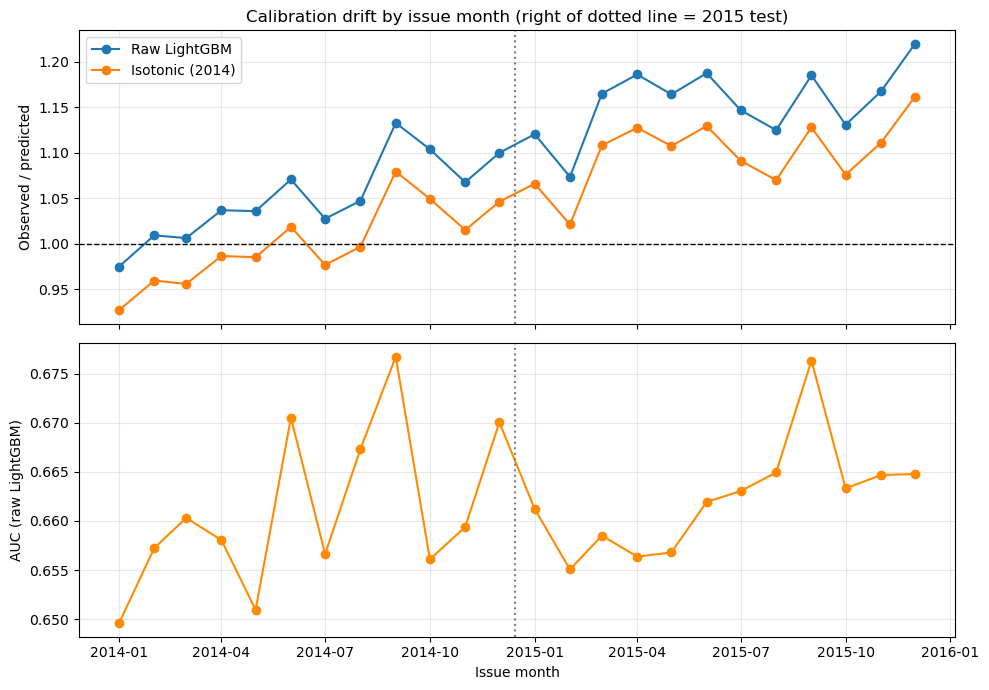

In [15]:
monthly_frame = pd.concat(
    [
        pd.DataFrame(
            {
                "issue_month": validation_ready["issue_month"].to_numpy(),
                "y": y_val,
                "raw": scores["LightGBM raw"]["val"],
                "iso": scores["LightGBM isotonic (fit on 2014)"]["val"],
            }
        ),
        pd.DataFrame(
            {
                "issue_month": test_ready["issue_month"].to_numpy(),
                "y": y_test,
                "raw": scores["LightGBM raw"]["test"],
                "iso": scores["LightGBM isotonic (fit on 2014)"]["test"],
            }
        ),
    ],
    ignore_index=True,
)

monthly_rows = []
for month, group in monthly_frame.groupby("issue_month"):
    monthly_rows.append(
        {
            "issue_month": month,
            "loans": len(group),
            "observed": group["y"].mean(),
            "mean_raw": group["raw"].mean(),
            "mean_isotonic": group["iso"].mean(),
            "obs_over_raw": group["y"].mean() / group["raw"].mean(),
            "obs_over_isotonic": group["y"].mean() / group["iso"].mean(),
            "auc_raw": roc_auc_score(group["y"], group["raw"]),
        }
    )

monthly = pd.DataFrame(monthly_rows).set_index("issue_month")
display(monthly.round(4))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(monthly.index, monthly["obs_over_raw"], marker="o", label="Raw LightGBM")
axes[0].plot(monthly.index, monthly["obs_over_isotonic"], marker="o", label="Isotonic (2014)")
axes[0].axhline(1.0, color="black", linestyle="--", linewidth=1)
axes[0].axvline(pd.Timestamp("2014-12-15"), color="grey", linestyle=":")
axes[0].set_ylabel("Observed / predicted")
axes[0].set_title("Calibration drift by issue month (right of dotted line = 2015 test)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(monthly.index, monthly["auc_raw"], marker="o", color="darkorange")
axes[1].axvline(pd.Timestamp("2014-12-15"), color="grey", linestyle=":")
axes[1].set_ylabel("AUC (raw LightGBM)")
axes[1].set_xlabel("Issue month")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(figures_dir / "04b_monthly_drift_2014_2015.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Save diagnostic tables
Regenerable report tables only. These are CSV files in `reports/tables/`; no model, preprocessor, policy or processed-data file is written or changed.

In [16]:
outputs = {
    "04b_discrimination.csv": discrimination,
    "04b_auc_bootstrap_ci_2015.csv": auc_ci,
    "04b_calibration_summary.csv": calibration,
    "04b_recalibration_alternatives_2015.csv": recalibration.reset_index(),
    "04b_psi_model_inputs.csv": psi_inputs,
    "04b_psi_score.csv": score_psi,
    "04b_drift_decomposition.csv": decomposition,
    "04b_monthly_drift.csv": monthly.reset_index(),
}

for filename, table in outputs.items():
    table.to_csv(tables_dir / filename, index=False)
    print("Saved:", filename)

Saved: 04b_discrimination.csv
Saved: 04b_auc_bootstrap_ci_2015.csv
Saved: 04b_calibration_summary.csv
Saved: 04b_recalibration_alternatives_2015.csv
Saved: 04b_psi_model_inputs.csv
Saved: 04b_psi_score.csv
Saved: 04b_drift_decomposition.csv
Saved: 04b_monthly_drift.csv


## Conclusion and handoff

**Discrimination:** On the 2015 test set, the raw unweighted LightGBM achieved an AUC of 0.6625 (Gini 0.3251, KS 0.2362), outperforming the logistic regression baseline (AUC 0.6569, Gini 0.3139, KS 0.2253). The paired AUC difference via bootstrap was +0.0057 (95% CI: +0.0045 to +0.0072), which safely excludes zero, confirming LightGBM's superior ranking ability.

**Calibration:** Both models under-predicted 2015 risk. The raw LightGBM had an observed/predicted ratio of 1.1570 and a calibration-in-the-large of 0.1762. The 2014-fitted isotonic mapping improved this slightly to an obs/pred ratio of 1.1008 (cal-in-the-large: 0.1167). While the isotonic model beat the raw model on Brier score by +0.00027 (95% CI: +0.00025 to +0.00030, safely excluding zero), it did *not* meaningfully beat simpler 2014-fitted recalibrations. The Isotonic, Intercept Shift, and Platt (2014) approaches all tied with a 2015 Brier score of 0.1216, and the Platt (2014 H2 only) model achieved the best Log Loss (0.3998).

**Stability:** The model's inputs were highly stable between the 2011-2013 training period and the 2015 test period. Only `verification_status` registered a PSI above 0.10 (0.1805, indicating moderate shift). Consequently, the predicted score distribution was exceptionally stable (PSI = 0.0013 for raw, 0.0012 for isotonic). Importantly, PSI measures distribution change, not its underlying cause.

**Drift Decomposition:** The rise in the observed charge-off rate from 2014 to 2015 (1.160 percentage points) was entirely driven by within-segment deterioration. Using the model's own score deciles, the rate effect accounted for +1.363 pp, easily overwhelming a slight negative mix effect (-0.203 pp). The trend is even more pronounced from the 2011-2013 training period to 2015 (Total change: 2.367 pp; Rate effect: 2.407 pp). Put simply, loans with the exact same predicted risk performed significantly worse in 2015. 

**Limitations:** 
* These diagnostics describe one 2011–2015 cohort of originated 36-month loans; they do not show the *cause* of drift (macroeconomic conditions, Lending Club's underwriting changes, investor demand, and borrower self-selection are all candidates). 
* The 2014 recalibration data utilized complete final outcomes, which in a live production setting would not yet have been observed for loans issued that recently. 
* The target is a recorded final status, not default within a fixed time horizon.

**Next:** `04c-Sensitivity-Feature-Policies.ipynb` tests how the results change when `verification_status`, `home_ownership`, and `addr_state` are removed. Notebook 05 will then use the recalibration choices made here.